References:
- `ChatGPT`,
- `https://www.kaggle.com/code/nghihuynh/cifar-10-mlp-cnn-resnet9-classifier`

In [16]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

### Configuration globale

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

### Paramètres

In [5]:
learning_rates = [0.01, 0.001, 0.0001]
activation_functions = {
    'ReLU': nn.ReLU,
    'Sigmoid': nn.Sigmoid,
    'Tanh': nn.Tanh,
    'LeakyReLU': nn.LeakyReLU
}
hidden_units = [128, 256, 512]

### Chargement des données CIFAR-10

In [6]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=100, shuffle=True)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=100, shuffle=False)

100%|██████████| 170498071/170498071 [00:15<00:00, 11056278.94it/s]


Extracting ./data/cifar-10-python.tar.gz to ./data
Files already downloaded and verified


### Modèle MLP défini avec une classe

In [7]:
class MLPModel(nn.Module):
    def __init__(self, input_size, hidden_units, activation):
        super(MLPModel, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(input_size, hidden_units)
        self.activation = activation()
        self.fc2 = nn.Linear(hidden_units, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.activation(x)
        x = self.fc2(x)
        return x

### Entraînement

In [8]:
def train_model(model, criterion, optimizer, num_epochs=10):
    model.train()
    train_losses = []
    for epoch in range(num_epochs):
        running_loss = 0.0
        for images, labels in trainloader:
            images, labels = images.to(device), labels.to(device)

            # Forward + Backward + Optimisation
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
        train_losses.append(running_loss / len(trainloader))
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss / len(trainloader):.4f}")
    return train_losses

### Évaluation

In [9]:
def evaluate_model(model):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

# Expérimentations
results = {}

### Combinaisons de paramètres

In [ ]:
for lr in learning_rates:
    for name, activation in activation_functions.items():
        for units in hidden_units:
            key = f"LR={lr}_Activation={name}_HiddenUnits={units}"
            print(f"\nTraining with parameters: Learning Rate={lr}, Activation={name}, Hidden Units={units}")
            model = MLPModel(32 * 32 * 3, units, activation).to(device)
            criterion = nn.CrossEntropyLoss()
            optimizer = optim.Adam(model.parameters(), lr=lr)
            train_model(model, criterion, optimizer)
            accuracy = evaluate_model(model)
            results[key] = {'accuracy': accuracy}


Training with parameters: Learning Rate=0.01, Activation=ReLU, Hidden Units=128
Epoch [1/10], Loss: 2.1350
Epoch [2/10], Loss: 2.0116
Epoch [3/10], Loss: 2.0295
Epoch [4/10], Loss: 1.9782
Epoch [5/10], Loss: 1.8964
Epoch [6/10], Loss: 1.8782
Epoch [7/10], Loss: 1.8947
Epoch [8/10], Loss: 1.8261
Epoch [9/10], Loss: 1.8171
Epoch [10/10], Loss: 1.7877

Training with parameters: Learning Rate=0.01, Activation=ReLU, Hidden Units=256
Epoch [1/10], Loss: 2.5183
Epoch [2/10], Loss: 2.5569
Epoch [3/10], Loss: 2.5763
Epoch [4/10], Loss: 2.4412
Epoch [5/10], Loss: 2.3621
Epoch [6/10], Loss: 2.2479
Epoch [7/10], Loss: 2.3329
Epoch [8/10], Loss: 2.2136
Epoch [9/10], Loss: 2.1638
Epoch [10/10], Loss: 2.1513

Training with parameters: Learning Rate=0.01, Activation=ReLU, Hidden Units=512
Epoch [1/10], Loss: 3.4676
Epoch [2/10], Loss: 4.1253
Epoch [3/10], Loss: 3.5946
Epoch [4/10], Loss: 3.7123
Epoch [5/10], Loss: 3.2218
Epoch [6/10], Loss: 3.6288
Epoch [7/10], Loss: 3.3967
Epoch [8/10], Loss: 3.3934

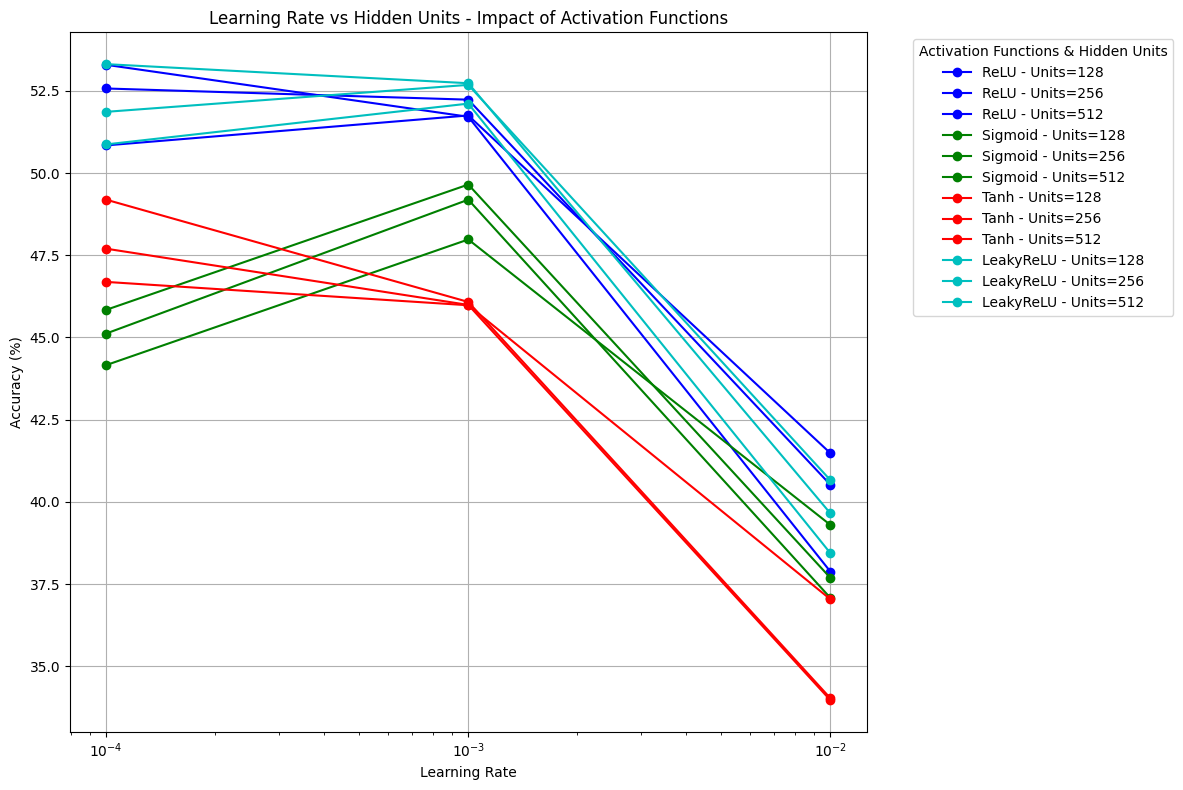

In [22]:
plt.figure(figsize=(12, 8))


colors = ['b', 'g', 'r', 'c'] 

for color, (name, activation) in zip(colors, activation_functions.items()):
    accuracies = np.zeros((len(learning_rates), len(hidden_units)))

    for i, lr in enumerate(learning_rates):
        for j, units in enumerate(hidden_units):
            key = f"LR={lr}_Activation={name}_HiddenUnits={units}"
            if key not in results:
                model = MLPModel(32 * 32 * 3, units, activation).to(device)
                criterion = nn.CrossEntropyLoss()
                optimizer = optim.Adam(model.parameters(), lr=lr)
                train_model(model, criterion, optimizer)
                accuracy = evaluate_model(model)
                results[key] = {'accuracy': accuracy}
            accuracies[i, j] = results[key]['accuracy']


    for i, units in enumerate(hidden_units):
        plt.plot(learning_rates, accuracies[:, i], marker='o', color=color, label=f'{name} - Units={units}')
    

plt.title('Learning Rate vs Hidden Units - Impact of Activation Functions')
plt.xlabel('Learning Rate')
plt.ylabel('Accuracy (%)')
plt.xscale('log')
plt.grid(True)


plt.legend(title='Activation Functions & Hidden Units', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('learning_rate_vs_hidden_units_plan.png', format='png', bbox_inches='tight')
plt.show()


### Résultats finaux

In [13]:
print("\nRésultats des expérimentations :")
for key, value in results.items():
    print(f"{key}: {value}")


Résultats des expérimentations :
LR=0.01_Activation=ReLU_HiddenUnits=128: {'accuracy': 41.48}
LR=0.01_Activation=ReLU_HiddenUnits=256: {'accuracy': 40.52}
LR=0.01_Activation=ReLU_HiddenUnits=512: {'accuracy': 37.88}
LR=0.01_Activation=Sigmoid_HiddenUnits=128: {'accuracy': 39.3}
LR=0.01_Activation=Sigmoid_HiddenUnits=256: {'accuracy': 37.08}
LR=0.01_Activation=Sigmoid_HiddenUnits=512: {'accuracy': 37.69}
LR=0.01_Activation=Tanh_HiddenUnits=128: {'accuracy': 37.04}
LR=0.01_Activation=Tanh_HiddenUnits=256: {'accuracy': 33.97}
LR=0.01_Activation=Tanh_HiddenUnits=512: {'accuracy': 34.03}
LR=0.01_Activation=LeakyReLU_HiddenUnits=128: {'accuracy': 38.44}
LR=0.01_Activation=LeakyReLU_HiddenUnits=256: {'accuracy': 40.66}
LR=0.01_Activation=LeakyReLU_HiddenUnits=512: {'accuracy': 39.65}
LR=0.001_Activation=ReLU_HiddenUnits=128: {'accuracy': 51.75}
LR=0.001_Activation=ReLU_HiddenUnits=256: {'accuracy': 52.23}
LR=0.001_Activation=ReLU_HiddenUnits=512: {'accuracy': 51.71}
LR=0.001_Activation=Sigmo